In [3]:
# %% Bibliotecas

import time

import pyro
import pyro.distributions as dist
import torch
import torch.distributions as tdist
from pyro.infer import MCMC, NUTS
from torch.distributions import Binomial, Normal, Poisson


c:\Users\rober\anaconda3\envs\tcc_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# %% Modelo gerador completo (usado apenas para simular os dados de teste)
# Mesma implementação da Seção 2.2 / cod_fonte01.py, mantida idêntica para
# garantir que NUTS e NPE sejam aplicados exatamente aos mesmos dados.

def simulate_model(lambda_, mu_q, sigma_q, n_arrastos=30):
    """Simula as quantidades latentes e as capturas dos arrastos."""
    n_disponiveis = Poisson(lambda_).sample((n_arrastos, 2))

    eta = Normal(mu_q, sigma_q).sample((n_arrastos,))
    q = torch.sigmoid(eta)

    capturas_por_rede = Binomial(
        total_count=n_disponiveis,
        probs=q[:, None],
    ).sample()
    y_total = capturas_por_rede.sum(dim=1)

    return n_disponiveis, eta, q, capturas_por_rede, y_total

In [6]:
# %% Priors (Seção 2.3) — idênticos aos usados no treinamento da NPE

prior_log_lambda = tdist.Uniform(
    torch.log(torch.tensor(20.0)), torch.log(torch.tensor(5000.0))
)
prior_mu_q = tdist.Uniform(torch.tensor(-6.0), torch.tensor(0.0))
prior_log_sigma_q = tdist.Uniform(
    torch.log(torch.tensor(0.2)), torch.log(torch.tensor(2.5))
)


def sample_priors():
    """Sorteia os parâmetros globais das distribuições a priori."""
    log_lambda = prior_log_lambda.sample()
    mu_q = prior_mu_q.sample()
    log_sigma_q = prior_log_sigma_q.sample()
    return torch.exp(log_lambda), mu_q, torch.exp(log_sigma_q)


In [22]:
# %% Modelo probabilístico em Pyro (Seção 2.4)
# Parametrização não centrada para eta_i: eta_i = mu_q + sigma_q * z_i,
# com z_i ~ Normal(0, 1). Isso melhora a eficiência de amostragem do NUTS
# sem alterar a estrutura do modelo (mesma distribuição marginal de eta_i).

def modelo_nuts(y_obs, n_arrastos=30):
    log_lambda = pyro.sample("log_lambda", dist.Uniform(
        torch.log(torch.tensor(20.0)), torch.log(torch.tensor(5000.0))
    ))
    mu_q = pyro.sample("mu_q", dist.Uniform(-6.0, 0.0))
    log_sigma_q = pyro.sample("log_sigma_q", dist.Uniform(
        torch.log(torch.tensor(0.2)), torch.log(torch.tensor(2.5))
    ))

    lambda_ = torch.exp(log_lambda)
    sigma_q = torch.exp(log_sigma_q)

    with pyro.plate("arrastos", n_arrastos):
        z = pyro.sample("z", dist.Normal(0.0, 1.0))
        eta = mu_q + sigma_q * z
        q = torch.sigmoid(eta).clamp(1e-6, 1 - 1e-6)
        rate = (2.0 * lambda_ * q).clamp(min=1e-6)
        pyro.sample("y", dist.Poisson(rate), obs=y_obs)

In [35]:
pyro.enable_validation(True)

num_chains = 4
num_warmup = 1000
num_samples = 1000

amostras_por_cadeia = []

for chain_id in range(num_chains):
    print(f"\nRodando cadeia {chain_id + 1} de {num_chains}...")
    pyro.set_rng_seed(chain_id)  # seed diferente por cadeia

    nuts_kernel = NUTS(modelo_nuts)
    mcmc_cadeia = MCMC(
        nuts_kernel,
        num_samples=num_samples,
        warmup_steps=num_warmup,
        num_chains=1,  # sempre 1 aqui — o loop é quem cuida das "várias cadeias"
    )
    mcmc_cadeia.run(y_total_test, n_arrastos=n_arrastos)
    amostras_por_cadeia.append(mcmc_cadeia.get_samples())

print("\nTodas as cadeias concluídas!")


Rodando cadeia 1 de 4...


Sample: 100%|██████████| 2000/2000 [29:46,  1.12it/s, step size=6.37e-03, acc. prob=0.949]



Rodando cadeia 2 de 4...


Sample: 100%|██████████| 2000/2000 [22:35,  1.48it/s, step size=7.02e-03, acc. prob=0.940]



Rodando cadeia 3 de 4...


Sample: 100%|██████████| 2000/2000 [26:27,  1.26it/s, step size=7.61e-03, acc. prob=0.946]



Rodando cadeia 4 de 4...


Sample: 100%|██████████| 2000/2000 [25:02,  1.33it/s, step size=6.94e-03, acc. prob=0.924]


Todas as cadeias concluídas!


In [24]:
# %% Simulação de um conjunto de dados de teste
# Usa o modelo gerador completo (com N_ir latente e captura binomial),
# não a forma marginalizada — assim o NUTS é testado contra dados gerados
# pelo processo biológico completo, e não pela sua própria aproximação.

torch.manual_seed(42)
pyro.set_rng_seed(42)

n_arrastos = 30

lambda_true, mu_q_true, sigma_q_true = sample_priors()
theta_true = torch.tensor(
    [torch.log(lambda_true), mu_q_true, torch.log(sigma_q_true)]
)

_, _, _, _, y_total_test = simulate_model(
    lambda_true, mu_q_true, sigma_q_true, n_arrastos=n_arrastos
)

print(f"Valores geradores: log(lambda)={theta_true[0]:.3f}, "
      f"mu_q={theta_true[1]:.3f}, log(sigma_q)={theta_true[2]:.3f}")


Valores geradores: log(lambda)=7.867, mu_q=-0.510, log(sigma_q)=-0.642


In [31]:
pip install arviz

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 1.7/1.7 MB 18.1 MB/s  0:00:00
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 19.1 MB/s  0:00:00
   ---------------------------------------- 0.0/3.2 MB ? eta -:--:--
   ---------------------------------------- 3.2/3.2 MB 26.9 MB/s  0:00:00

   ---------------------------------------- 0/5 [h5py]
   ---------------------------------------- 0/5 [h5py]
   -------- ------------------------------- 1/5 [h5netcdf]
   ---------------- ----------------------- 2/5 [xarray]
   ---------------- ----------------------- 2/5 [xarray]
   ---------------- ----------------------- 2/5 [xarray]
   ---------------- ----------------------- 2/5 [xarray]
   ---------------- ----------------------- 2/5 [xarray]
   ---------------- ----------------------- 2/5 [xarray]
   ---------------- ----------------------- 2/5 [xarray]
  

In [41]:
import arviz as az
import numpy as np

dados_az = {
    param: np.stack([amostras_por_cadeia[c][param].numpy() for c in range(num_chains)])
    for param in ["log_lambda", "mu_q", "log_sigma_q"]
}
idata = az.from_dict(posterior=dados_az)
print(az.summary(idata))

              mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
log_lambda   8.080  0.268   7.651    8.517      0.016    0.007     262.0   
mu_q        -0.806  0.404  -1.448   -0.113      0.026    0.011     234.0   
log_sigma_q -1.085  0.198  -1.442   -0.723      0.014    0.009     198.0   

             ess_tail  r_hat  
log_lambda      309.0   1.01  
mu_q            286.0   1.01  
log_sigma_q     518.0   1.01  


In [48]:
# %% Extração das amostras posteriores para comparação com a NPE

theta_nuts = torch.stack([
    torch.cat([amostras_por_cadeia[c]["log_lambda"] for c in range(num_chains)]),
    torch.cat([amostras_por_cadeia[c]["mu_q"] for c in range(num_chains)]),
    torch.cat([amostras_por_cadeia[c]["log_sigma_q"] for c in range(num_chains)]),
], dim=1)

print(f"\nAmostras posteriores obtidas via NUTS: {theta_nuts.shape[0]}")


Amostras posteriores obtidas via NUTS: 4000


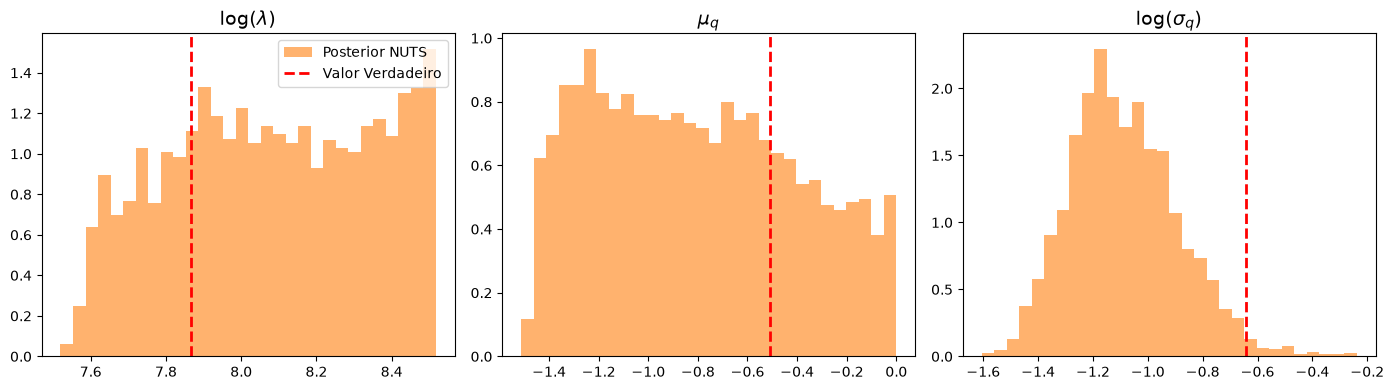

In [49]:
# %% Validação visual — Posteriores NUTS vs valores geradores

import matplotlib.pyplot as plt

param_names = [r"$\log(\lambda)$", r"$\mu_q$", r"$\log(\sigma_q)$"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for i in range(3):
    axes[i].hist(
        theta_nuts[:, i].numpy(), bins=30, density=True, alpha=0.6,
        color="tab:orange", label="Posterior NUTS",
    )
    axes[i].axvline(
        theta_true[i].item(), color="red", linestyle="--", linewidth=2,
        label="Valor Verdadeiro",
    )
    axes[i].set_title(param_names[i], fontsize=14)
    if i == 0:
        axes[i].legend()

plt.tight_layout()
plt.show()


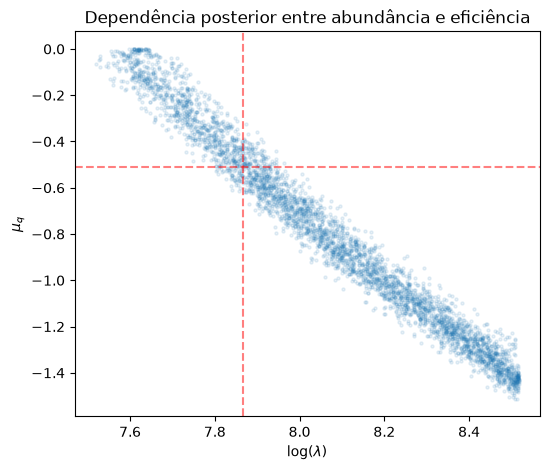

Correlação log(lambda) vs mu_q: -0.987


In [47]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(theta_nuts[:, 0].numpy(), theta_nuts[:, 1].numpy(), alpha=0.1, s=5)
ax.axvline(theta_true[0].item(), color="red", linestyle="--", alpha=0.5)
ax.axhline(theta_true[1].item(), color="red", linestyle="--", alpha=0.5)
ax.set_xlabel(r"$\log(\lambda)$")
ax.set_ylabel(r"$\mu_q$")
ax.set_title("Dependência posterior entre abundância e eficiência")
plt.show()

# Correlação numérica, como pedido na Seção 2.11
corr = np.corrcoef(theta_nuts[:, 0].numpy(), theta_nuts[:, 1].numpy())[0, 1]
print(f"Correlação log(lambda) vs mu_q: {corr:.3f}")

In [1]:
print(all(v in globals() for v in ["theta_true", "y_total_test", "theta_nuts", "t_nuts"]))
print(theta_nuts.shape)  # esperado: torch.Size([4000, 3])

False


NameError: name 'theta_nuts' is not defined